# 06 – Merge and quality checks  
**Input:** `food_clean.csv` (02_Cleaning), `violation_features.csv` (03_Violations), `history_features.csv` (04_History)
**Output:** `food_final.csv` (2015–2022), the final dataset for the model

## 1. Merge the three files

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

pandas for the tables and matplotlib for the box plots in the outlier check

In [3]:
clean = pd.read_csv('food_clean.csv')
print(clean.shape)

(212463, 22)


The clean file: one row per real inspection, with the original columns plus Business_ID, First_Seen_Date, Year, Fail and Period, **212,463 rows and 22 columns** (2010–2022, the early years are kept for the history)

In [4]:
viol_feat = pd.read_csv('violation_features.csv')
print(viol_feat.shape)

(212463, 19)


The violation features (counts, severity levels, topics, previous-visit columns): **212,463 rows and 19 columns**.

In [5]:
hist_feat = pd.read_csv('history_features.csv')
print(hist_feat.shape)

(212463, 14)


The history and calendar features: **212,463 rows and 14 columns**

In [6]:
print(clean['Inspection ID'].duplicated().sum(), viol_feat['Inspection ID'].duplicated().sum(), hist_feat['Inspection ID'].duplicated().sum())

0 0 0


Before merging we check that `Inspection ID` is unique in each file, so every inspection appears only once, all three numbers should be 0

In [7]:
final = clean.merge(viol_feat, on='Inspection ID', how='inner', validate='one_to_one')
final = final.merge(hist_feat, on='Inspection ID', how='inner', validate='one_to_one')
print(final.shape)

(212463, 53)


We join the three files on `Inspection ID` (`merge` puts the columns of two tables side by side, matching rows with the same ID)`validate='one_to_one'` stops with an error if an ID appears twice, Result: 212,463 rows (the same as the clean file) and 53 columns

## 2. Quality checks

In [8]:
print(len(final) == len(clean) == len(viol_feat) == len(hist_feat))

True


Quality check 1: no rows were lost or added by the merge (should print True)

### Keep the study years
The history columns were calculated on 2010–2022, so every business has its real earlier visits, now we keep only the years we study

In [9]:
final = final[(final['Year'] >= 2015) & (final['Year'] <= 2022)]
print(final.shape)

(126787, 53)


We keep 2015–2022: **126,787 rows and 53 columns**, the same number of inspections as before, but now with complete history columns.

In [10]:
final.isnull().sum()[final.isnull().sum() > 0]

AKA Name        327
City             46
State            34
Zip               1
Violations    17814
Latitude        455
Longitude       455
Location        455
dtype: int64

Quality check 2: only descriptive columns we do not use have missing values and Violations (17,814, empty = no violations), All feature columns have 0 missing values

In [11]:
final['Inspection Date'] = pd.to_datetime(final['Inspection Date'])
print(final['Inspection Date'].min(), final['Inspection Date'].max())

2015-01-02 00:00:00 2022-12-30 00:00:00


Quality check 3: the dates are between 1 January 2015 and 31 December 2022

In [12]:
final['Results'].value_counts()

Results
Pass                  68884
Pass w/ Conditions    29548
Fail                  28355
Name: count, dtype: int64

Quality check 4: only the three real results are left.

### Quality check 5 – Outliers
We check the numeric columns in two steps: first impossible values (errors), then outliers with the IQR

In [13]:
num_cols = ['Num_Violations', 'Num_Critical', 'Num_Serious', 'Prev_Num_Violations',
            'Days_Since_Last', 'Days_Since_First_Seen', 'Num_Past_Inspections']
(final[num_cols] < 0).sum()

Num_Violations           0
Num_Critical             0
Num_Serious              0
Prev_Num_Violations      0
Days_Since_Last          0
Days_Since_First_Seen    0
Num_Past_Inspections     0
dtype: int64

Impossible values: a count of violations or a number of days can never be negative, Result: all 7 columns show 0, so there are no impossible values

In [14]:
final[num_cols].describe().round(1)

,Num_Violations,Num_Critical,Num_Serious,Prev_Num_Violations,Days_Since_Last,Days_Since_First_Seen,Num_Past_Inspections
count,126787.0,126787.0,126787.0,126787.0,126787.0,126787.0,126787.0
mean,4.0,0.2,0.8,3.7,265.6,1649.4,7.1
std,3.6,0.6,1.3,3.6,261.7,1267.0,6.2
min,0.0,0.0,0.0,0.0,1.0,0.0,0.0
25%,1.0,0.0,0.0,1.0,52.0,478.0,2.0
50%,3.0,0.0,0.0,3.0,231.0,1636.0,6.0
75%,6.0,0.0,1.0,5.0,367.0,2541.0,11.0
max,34.0,6.0,16.0,34.0,4432.0,4740.0,58.0


Summary of the numeric columns: the maximum is much bigger than the 75% value in: Num_Violations (75% = 6, max = 34), Num_Serious (1 vs 16), Prev_Num_Violations (5 vs 34), Days_Since_Last (367 vs 4,432 days) and Num_Past_Inspections (11 vs 58), Days_Since_First_Seen is more even (2,541 vs 4,740)

In [15]:
for col in num_cols:
    q1 = final[col].quantile(0.25)
    q3 = final[col].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - (1.5 * iqr)
    upper_fence = q3 + (1.5 * iqr)
    n_out = ((final[col] < lower_fence) | (final[col] > upper_fence)).sum()
    print(f'{col}: fences {lower_fence:.1f} to {upper_fence:.1f}, outliers = {n_out} ({n_out / len(final) * 100:.1f}%)')

Num_Violations: fences -6.5 to 13.5, outliers = 2895 (2.3%)
Num_Critical: fences 0.0 to 0.0, outliers = 19780 (15.6%)
Num_Serious: fences -1.5 to 2.5, outliers = 12311 (9.7%)
Prev_Num_Violations: fences -5.0 to 11.0, outliers = 4827 (3.8%)
Days_Since_Last: fences -420.5 to 839.5, outliers = 3105 (2.4%)
Days_Since_First_Seen: fences -2616.5 to 5635.5, outliers = 0 (0.0%)
Num_Past_Inspections: fences -11.5 to 24.5, outliers = 1730 (1.4%)


IQR method: a value below Q1 − 1.5·IQR or above Q3 + 1.5·IQR is an outlier, Result: Num_Violations 2,895 (2.3%), Num_Serious 12,311 (9.7%), Prev_Num_Violations 4,827 (3.8%), Days_Since_Last 3,105 (2.4%), Num_Past_Inspections 1,730 (1.4%), Days_Since_First_Seen 0, For Num_Critical both fences are 0, because more than 75% of the inspections have no critical violation, so every critical violation counts as an "outlier" (19,780, 15.6%) so the IQR method does not make sense for this column

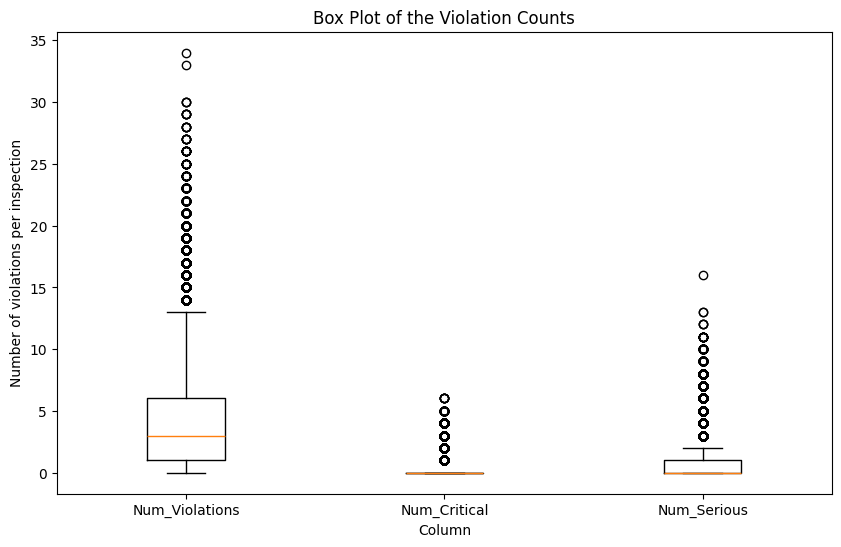

In [16]:
plt.figure(figsize=(10, 6))
plt.boxplot([final['Num_Violations'], final['Num_Critical'], final['Num_Serious']])
plt.xticks([1, 2, 3], ['Num_Violations', 'Num_Critical', 'Num_Serious'])
plt.title('Box Plot of the Violation Counts')
plt.xlabel('Column')
plt.ylabel('Number of violations per inspection')
plt.show()

Box plot of the violation counts: The boxes are small and close to 0 (most inspections have 1–6 violations and no critical or serious one), and there are many points above the whiskers, up to 34 violations and 16 serious violations

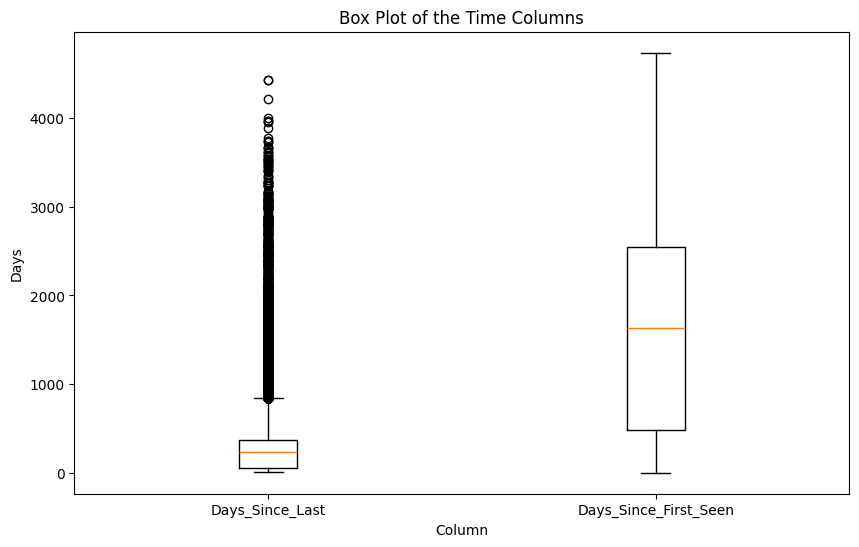

In [17]:
plt.figure(figsize=(10, 6))
plt.boxplot([final['Days_Since_Last'], final['Days_Since_First_Seen']])
plt.xticks([1, 2], ['Days_Since_Last', 'Days_Since_First_Seen'])
plt.title('Box Plot of the Time Columns')
plt.xlabel('Column')
plt.ylabel('Days')
plt.show()

Box plot of the time columns (in days, so in a separate plot because the scale is very different), Days_Since_Last has many points above the upper whisker (gaps longer than about 840 days), Days_Since_First_Seen has no outliers

In [18]:
q1 = final['Num_Violations'].quantile(0.25)
q3 = final['Num_Violations'].quantile(0.75)
upper_fence = q3 + (1.5 * (q3 - q1))
is_outlier = final['Num_Violations'] > upper_fence
is_outlier.groupby(final['Period']).mean().round(3)

Period
Grace (90 days)    0.063
Late transition    0.069
Post               0.035
Pre                0.003
Name: Num_Violations, dtype: float64

Share of inspections with an outlier number of violations (more than 13) in each period: Result: Pre 0.3%, Grace 6.3%, Late transition 6.9%, Post 3.5%, long violation lists are about 12 times more common after the change than before, so they are part of the effect we study

**Decision – we keep the outliers, for these reasons:**
- They are real inspections, not typing errors: there are no impossible (negative) values, and a business can really get many violations or go a long time without an inspection
- The long violation lists are part of what we study: they became much more common after the 2018 change, removing them would hide the effect we test in H1b
- Our test for the number of violations (Mann–Whitney U) uses ranks, so outliers do not distort it
- For the model, decision trees are not sensitive to outliers, if we use logistic regression we can cap the extreme values then

### Quality check 6 – Distribution shape
The box plots show the outliers, here we look at the shape of the numeric columns, the shape decides which tests we can use: a t-test compares means and assumes normal data, which skewed data does not meet

In [19]:
final[num_cols].skew().round(2)

Num_Violations           1.48
Num_Critical             3.11
Num_Serious              2.34
Prev_Num_Violations      1.49
Days_Since_Last          3.42
Days_Since_First_Seen    0.35
Num_Past_Inspections     1.25
dtype: float64

`skew()` gives the skewness of each column (Chapter 6): 0 = symmetric (like a normal distribution), > 0 = right-skewed (long tail to the right), < 0 = left-skewed. Result: Num_Violations 1.48, Num_Critical 3.11, Num_Serious 2.34, Prev_Num_Violations 1.49, Days_Since_Last 3.42, Days_Since_First_Seen 0.35, Num_Past_Inspections 1.25. All columns are right-skewed; the strongest are Days_Since_Last (3.42) and Num_Critical (3.11). Only Days_Since_First_Seen (0.35) is almost symmetric.

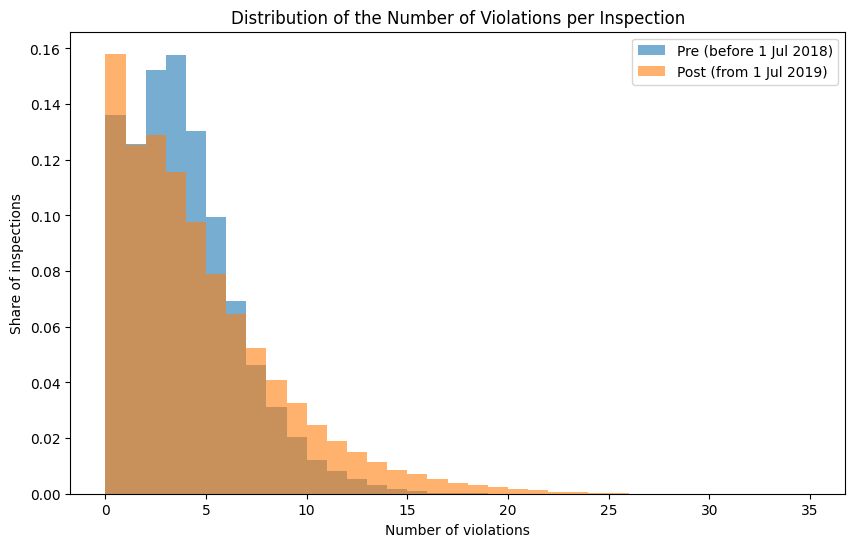

In [20]:
pre_v = final[final['Period'] == 'Pre']['Num_Violations']
post_v = final[final['Period'] == 'Post']['Num_Violations']
plt.figure(figsize=(10, 6))
plt.hist(pre_v, bins=35, range=(0, 35), alpha=0.6, density=True, label='Pre (before 1 Jul 2018)')
plt.hist(post_v, bins=35, range=(0, 35), alpha=0.6, density=True, label='Post (from 1 Jul 2019)')
plt.title('Distribution of the Number of Violations per Inspection')
plt.xlabel('Number of violations')
plt.ylabel('Share of inspections')
plt.legend()
plt.show()

Histogram of the number of violations before and after the change (`density=True` shows shares, so the two periods can be compared even though they have different sizes). Result: in both periods most inspections have 0–6 violations and there is a long tail to the right. After the change there are more inspections with 0–1 violations and also more with 7 or more, while before the change more inspections had 2–6 violations, so after the change the number of violations is more spread out. The long tail to the right matches with the positive skewness (1.48 for Num_Violations, all periods).

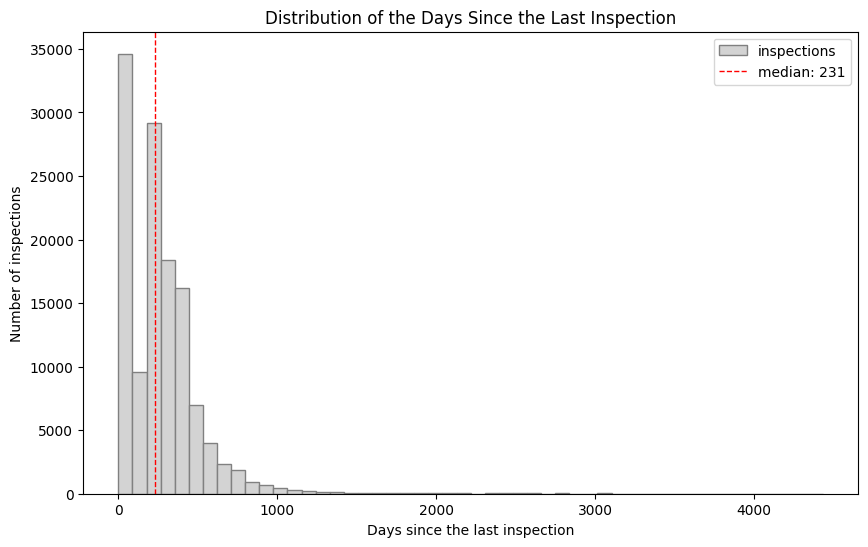

In [21]:
plt.figure(figsize=(10, 6))
plt.hist(final['Days_Since_Last'], bins=50, color='lightgray', edgecolor='grey', label='inspections')
plt.title('Distribution of the Days Since the Last Inspection')
plt.xlabel('Days since the last inspection')
plt.ylabel('Number of inspections')
plt.axvline(final['Days_Since_Last'].median(), color='red', linestyle='dashed', linewidth=1, label='median: {0:.0f}'.format(final['Days_Since_Last'].median()))
plt.legend()
plt.show()

Histogram of the days since the last inspection. Result: most inspections come either soon after the previous one (the first bar: mostly re-inspections a few days or weeks after a fail) or after about 6–12 months (routine visits). The second tall bar also contains the first inspections, which were filled with the median (231 days). A few gaps are longer than 1,000 days (up to about 4,400), so the column has a long right tail (skewness 3.42).

Conclusion: the numeric columns are not normal, they are right-skewed (all except Days_Since_First_Seen, which is almost symmetric): most values are small and a few are very large, so the mean is pulled up and is bigger than the median, therefore when we compare numeric columns between groups we use the median and the non-parametric Mann–Whitney U test (it uses ranks) instead of the t-test, the chi-square tests are not affected, because they use categories, not numbers

In [22]:
final['Fail'].mean().round(3)

np.float64(0.224)

The share of failed inspections in the final dataset (the target): 0.224, so about 1 in 5 inspections fails, the classes are unbalanced, this matters for the model

In [23]:
final['Is_Reinspection'] = final['Is_Reinspection'].astype(int)
final.to_csv('food_final.csv', index=False)
print(final.shape)

(126787, 53)


We save the final dataset, `Is_Reinspection` is stored as 0/1 like the other yes/no columns, the meaning of every column is in `README.md`